# QC0426 / VTI — Measurement

**QC0426** (trilayer graphene, stacking under investigation) on the
**VTI** rig.

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** contain `<PLACEHOLDER>` values or pending decisions — review
before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205
from drivers.async_station import async_station

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\aaron\\20260617-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.002 Tesla
Current:             : 0.018 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')  # <-- verify address
print(heater.sample_temperature())
print(heater.vaporizer_temperature())

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.43s
1.165
0.0


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_bg = Keithley_2400('k_bg', 'GPIB0::24::INSTR')  # <-- verify address — back gate
k_bg.mode.set('VOLT')
k_bg.volt.set(0)
k_bg.rangei.set(1e-6)
k_bg.rangev.set(21)
k_bg.volt.step = 0.005

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [7]:
k_2410 = Keithley_2400('k_2410', 'GPIB0::25::INSTR')  # <-- verify address — Si global gate
k_2410.mode.set('VOLT')
k_2410.volt.set(0)
k_2410.rangei.set(1e-6)
k_2410.rangev.set(21)
k_2410.volt.step = 0.005

Connected to: KEITHLEY INSTRUMENTS INC. 2410 (serial:1293333, firmware:C30   Mar 17 2006 09:29:29/A02  /J/J) in 0.03s


## DC205 (top gate)

In [8]:
k_tg = SRS_DC205("k_tg", "ASRL7::INSTR")  # <-- verify address — top gate
k_tg.ramp_rate = 2  # V/s

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s


In [9]:
# Sweepable top-gate parameter — appears in the data as column 'DC_bias'.
def dcbias(vg):
    k_tg.ramp_voltage(vg)

dc205_volt = qcodes.Parameter('DC_bias', unit='V', set_cmd=dcbias)

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# Gate validators — QC0426 GATE OPERATING LIMITS (see device card).
# Provided operating limits, not range-found this session (range-finding
# is blocklisted — see the brief). Commit exactly the device-card numbers.
TG_MIN, TG_MAX = -6.0, +7.0   # top gate (dc205_volt / k_tg), V — provided
BG_MIN, BG_MAX = -4.5, +4.5   # back gate (k_bg), V — provided
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (k_2410), V — provided
dc205_volt.vals = validators.Numbers(TG_MIN, TG_MAX)
# Instrument-level TG limit: direct k_tg.voltage()/ramp_voltage() calls
# bypass the dc205_volt wrapper; ramp steps also go through k_tg.voltage.
k_tg.voltage.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
k_2410.volt.vals = validators.Numbers(SI_MIN, SI_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.mag is a qcodes Parameter,
# so this validator rejects any magnet.mag(target) with |B| > B_SESSION_CAP
# before any hardware traffic. (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla
magnet.mag.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item, unestablished this session.
T_SESSION_CAP = 310.0  # K  # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)


# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
cst_epsilon0 = cst.epsilon_0
cst_e = cst.e
cst_h = cst.h
cst_phi0 = cst_h/(2*cst_e)
cst_kappa_SiO2 = 3.9
cst_kappa_hBN = 3

def calc_ctg(t_tg):
    """
    Calculates area capacitance for a top gate
    """
    return cst_epsilon0*cst_kappa_hBN/t_tg

def calc_cbg(t_bg, t_bgSiO2):
    """
    Calculates area capacitance for a back gate
    For a metal back gate, set t_bgSiO2 = 0
    """
    return cst_epsilon0*1/(t_bg/cst_kappa_hBN + t_bgSiO2/cst_kappa_SiO2)

def calc_nD(V_tg, V_bg, c_tg, c_bg, n_offset=0, D_offset = 0):
    n = (1/cst_e) * (c_tg*V_tg  + c_bg*V_bg) + n_offset
    D = 0.5*(c_tg*V_tg - c_bg*V_bg)*1/cst_epsilon0 + D_offset
    return n, D


# QC0426 gate stack geometry (fabrication facts; GEOMETRY PRIOR ONLY —
# calibrate via cnp-and-dline-calibration before trusting derived scales).
# SiO2 term zeroed — (n, D) uses the hBN top + back gates only; the Si
# gate (k_2410) is a screening gate.
t_tg = 15.6e-9  # m
t_bg = 12e-9    # m
t_bgSiO2 = 0    # m — zeroed for QC0426

c_tg = calc_ctg(t_tg)
c_bg = calc_cbg(t_bg, t_bgSiO2)

# Measurement config

In [13]:
# QC0426 measurement config — SKELETON. Contact pairs are per-run: set
# them per run (or let ContactMux write the mc_fragment once the QSwitch
# is live). Always set 'comments' per run — structured, current, no
# inherited text.
meas_config = {
    "sr0": "drain current on <CONTACT>",  # <-- set per wiring
    "sr0_gain": -1e6,  # ithaco gain
    "sr1": "<PAIR>",
    "sr2": "<PAIR>",
    "sr3": "<PAIR>",
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": heater.sample_temperature(),  # key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": k_2410.volt(),
    "comments": "<SET PER RUN>",
}

## QSwitch (contact mux) — LIVE

Bring-up complete (`qswitch-smoke-test.md` step 7): QSwitch on **ASRL4**,
Si standing closures on lines **16/11** confirmed closed, `settle_s` =
**4 s**. Maps below are the device card's, as deployed. `qsw.reset()` is
**always forbidden** — it opens the standing closures and drops the Si
gate.

In [14]:
from drivers.QSwitch import QSwitch
from drivers.contact_mux import ContactMux

qsw = QSwitch('qswitch', 'ASRL4::INSTR')

# Contact label -> QSwitch line (= F1 fischer index). Si lines 16/11 are
# EXCLUDED (standing closures, not managed); TG/BG are hardwired off-switch.
LINES = {
    "T1": 1,  "T2": 3,  "T3": 4,  "T4": 6,  "T5": 7,  "T6": 12, "T7": 13,
    "B1": 8,  "B2": 17, "B3": 23, "B4": 22, "B5": 20, "B6": 19, "B7": 18, "B8": 15,
}
# Instrument port -> front-panel BNC tap.
BREAKOUTS = {
    "source": 7, "drain": 8,
    "sr1+": 1, "sr1-": 2, "sr2+": 3, "sr2-": 4, "sr3+": 5, "sr3-": 6,
}
SETTLE_S = 4

mux = ContactMux(qsw, lines=LINES, breakouts=BREAKOUTS, settle_s=SETTLE_S)
# qsw.reset() ALWAYS FORBIDDEN — drops the Si gate (lines 16/11).

Connected to: Quantum Machines QSwitch (serial:37, firmware:2.0) in 0.06s


## HERA — E1 preflight probe (read-only; my designated first-E1 execute)

Bring-up is verified from the setup-section outputs (Gate A: all instruments
connected, sample T 1.17 K, magnet 0 T / PS heater on; Gate B: SAFETIES exec
[10], validators = device-card limits exactly, B cap 8.0 T). This cell is the
VERIFY-item-5 kernel-binding probe — **read-only, no gate/field/mux writes** —
and it snapshots the remaining VERIFY reads (magnet set-vs-read, sample T,
gate setpoints + committed validators, lock-in tau/filter-slope for the
settling record) in one place.

Per the brief this probe is my **first E1 execute**: I run it once you give
"go for autonomy" to confirm the kernel binding before any hardware move.
Staging it now so you can see exactly what that first autonomous action is.
~2 s, no instrument state changes. Awaiting the grant.


In [15]:
# === HERA E1 preflight — read-only namespace + state probe (first E1 execute) ===
# Confirms this kernel is the operator's instrument-carrying kernel and
# snapshots the session-start VERIFY reads. READ-ONLY: no gate/field/mux writes.

# 1) Kernel binding — the instruments are live objects in THIS kernel
need = ['magnet','heater','sr0','sr1','sr2','sr3','k_bg','k_2410','k_tg','qsw','mux','dc205_volt']
missing = [n for n in need if n not in globals()]
assert not missing, f'KERNEL-BINDING FAIL: missing {missing}'
print('namespace OK:', {n: type(globals()[n]).__name__ for n in ['magnet','heater','qsw','mux']})

# 2) Magnet — set-vs-read (VERIFY 1) + committed field-cap validator (Gate B)
print('magnet.mag() [measured] =', magnet.mag(), 'T')
print('magnet._status() =', magnet._status())
print('magnet.mag.vals =', magnet.mag.vals)

# 3) Temperature (VERIFY 3)
print('sample_T =', heater.sample_temperature(), 'K | vaporizer_T =', heater.vaporizer_temperature(), 'K')

# 4) Gate setpoints + committed validators (Gate B readback).
#    dc205_volt has no get_cmd -> read k_tg.voltage() for the TG value.
print('TG k_tg.voltage =', k_tg.voltage(), 'V | val', k_tg.voltage.vals)
print('BG k_bg.volt    =', k_bg.volt(), 'V | val', k_bg.volt.vals)
print('Si k_2410.volt  =', k_2410.volt(), 'V | val', k_2410.volt.vals, '| ramp step', k_2410.volt.step, 'V')

# 5) Lock-in settling — record tau + filter_slope at bring-up
#    (rig card: kit does NOT set these; run metadata stores them as None,
#     so this print is the only on-disk record of tau this session)
for s_ in [sr0, sr1, sr2, sr3]:
    print(f'{s_.name}: tau={s_.time_constant()}s slope={s_.filter_slope()} '
          f'sens={s_.sensitivity()} f={s_.frequency()}Hz ampl={s_.amplitude()}V')

# 6) QSwitch identity (Si standing closures on lines 16/11 validated at bring-up
#    per device card; qsw.reset() is ALWAYS forbidden — would drop the Si gate)
print('qsw IDN:', qsw.IDN())


namespace OK: {'magnet': 'FastBi1K5', 'heater': 'Lakeshore_335', 'qsw': 'QSwitch', 'mux': 'ContactMux'}
magnet.mag() [measured] = 0.002485739726027397 T
magnet._status() = {'voltage': -0.0002392, 'field': 0.0024865068493150687, 'output_enabled': True, 'persistent_switch_on': True, 'loop_mode': 'CC', 'update_mode': 'NORMAL'}
magnet.mag.vals = <Numbers -8.0<=v<=8.0>
sample_T = 1.165 K | vaporizer_T = 0.0 K
TG k_tg.voltage = 0.0 V | val <Numbers -6.0<=v<=7.0>


BG k_bg.volt    = 0.0 V | val <Numbers -4.5<=v<=4.5>
Si k_2410.volt  = 0.0 V | val <Numbers -50.0<=v<=50.0> | ramp step 0.005 V
sr0: tau=0.3s slope=24 sens=0.01 f=12.9995Hz ampl=0.004V
sr1: tau=0.3s slope=24 sens=0.0002 f=13.0Hz ampl=0.5V
sr2: tau=0.3s slope=24 sens=0.0002 f=13.0Hz ampl=0.004V


sr3: tau=0.3s slope=24 sens=0.0002 f=13.0005Hz ampl=0.004V
qsw IDN: {'vendor': 'Quantum Machines', 'model': 'QSwitch', 'serial': '37', 'firmware': '2.0'}


## HERA — Gate C: cheap liveness on the provided contacts (E1 auto)

First-session branch (no reference runs). Routes the provided contact config
(src T2 / drain B7, Rxx on T3–T4 & B4–B5, Rxy T5–B6) and takes a short
**TG trace at BG=Si=0, B=0** to confirm the device is alive before committing
to the 0 T gate map. This is the **liveness** half of `gate-current-sanity-check`
— **not** the range-finding/leakage walk (blocklisted; the operating limits are
provided as safe). TG stays inside the provided validator (−3..+3 V of [−6,+7]).

What I read from it: current-bias (5 nA) means the **Rxx voltage channels
(sr1/sr2) carry the modulation** (a CNP peak as TG crosses neutrality), while
sr0 (drain current) holds ~constant — that's the alive signature. Channels must
be independent (not all identical → grounded-device short) and BG/Si leakage at
the pA floor. I set sr1/2/3 sens to 5 mV so a high-R CNP peak doesn't overload;
reversible config choice.

~3 min (61 pts × 2 s + overhead). E1 auto — in-envelope, passes preconditions,
no consent gate. Executing now; I'll read the run from disk and report before
designing the gate map.


In [16]:
# === Gate C — cheap liveness on the provided contact configuration ===
# E1 auto: ContactMux routing + a small in-validator TG trace at B=0, BG=Si=0.
# Confirms (1) current passes, (2) Rxx channels live and modulate with gate,
# (3) channels independent (no grounded-device short), (4) BG/Si leakage at floor.
# NOT range-finding (blocklisted): TG stays well inside the provided [-6,+7] V
# validator (sweep -3..+3 V). Current-bias (5 nA) -> modulation is in the Rxx
# voltage channels; sr0 (drain current) should stay ~constant.

# --- preconditions (state this cell assumes but does not set) ---
B0 = magnet.mag(); T0 = heater.sample_temperature()
assert abs(B0) < 0.01, f'field not ~0: {B0} T'
assert T0 < 1.5,       f'T not at base: {T0} K'
assert abs(k_bg.volt()) < 1e-6 and abs(k_2410.volt()) < 1e-6, 'BG/Si not parked at 0'
print(f'preconditions OK: B={B0:.4f} T, T={T0:.3f} K, BG={k_bg.volt()} V, Si={k_2410.volt()} V')

# --- route the provided contacts (Si 16/11 standing closures are unmanaged/untouched) ---
mux.select({"source": "T2", "drain": "B7",
            "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5",
            "sr3+": "T5", "sr3-": "B6"})
print('routed:', mux.mc_fragment())

# --- lock-in sensitivity: 5 mV headroom on the Rxx/Rxy channels so a CNP peak
#     (R up to ~1 MOhm at 5 nA bias) does not overload. Config choice, reversible.
for s_ in (sr1, sr2, sr3):
    s_.sensitivity(0.005)

# --- per-run measurement config (structured, current; no inherited text) ---
meas_config["sr0"] = "drain current on B7 (Ithaco x-1e6)"
meas_config["sr1"] = "Rxx T3-T4"
meas_config["sr2"] = "Rxx B4-B5"
meas_config["sr3"] = "Rxy T5-B6"
meas_config["bias_voltage"] = sr1.amplitude()
meas_config["lockin_freq"] = sr1.frequency()
meas_config["sr0_sens"] = sr0.sensitivity()
meas_config["sr1_sens"] = sr1.sensitivity()
meas_config["sr2_sens"] = sr2.sensitivity()
meas_config["sr3_sens"] = sr3.sensitivity()
meas_config["sample_temperature:"] = heater.sample_temperature()
meas_config["Si (V)"] = k_2410.volt()
meas_config["comments"] = ("Gate C liveness: TG -3..+3 V, BG=Si=0, B=0, "
                           "provided config src T2/drain B7; sr1/2/3 sens 5 mV")

# --- build station fresh (comments are station-lifetime; rebuild per intent) ---
s = async_station(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment('Gate C liveness - provided contact config; TG trace BG=Si=0 B=0')

s.ramp(k_bg.volt, 0.0)   # BG already 0; never s.ramp(dc205_volt) -> it has no get

s.fp(heater.sample_temperature)
s.fp(k_bg.curr)
s.fp(k_2410.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)

s.plot(dc205_volt, sr1.X)
s.plot(dc205_volt, sr2.X)
s.plot(dc205_volt, sr0.X)

# TG sweep -3 -> +3 V (well inside validator), 61 pts, 2.0 s dwell (~settling floor)
try:
    s.sweep(dc205_volt, spoints(-3.0, 3.0, 61), delay=2.0)
finally:
    dc205_volt(0.0)   # park TG via direct set (s.ramp would call the missing get)
print('Gate C liveness sweep done; TG parked at 0.')


preconditions OK: B=0.0025 T, T=1.165 K, BG=0.0 V, Si=0.0 V


routed: {'qswitch_routing': {'source': 'T2', 'drain': 'B7', 'sr1+': 'T3', 'sr1-': 'T4', 'sr2+': 'B4', 'sr2-': 'B5', 'sr3+': 'T5', 'sr3-': 'B6'}, 'qswitch_state': '(@2!0,5!0,9!0:10!0,14!0,21!0,24!0,11!9,16!9,4!1,6!2,22!3,20!4,7!5,19!6,3!7,18!8)', 'sr1': 'T3-T4', 'sr2': 'B4-B5', 'sr3': 'T5-B6', 'sr0': 'drain current on B7', 'qswitch_source': 'source current on T2'}


2026-06-17 13:34:54,282 [INFO] Ramping k_bg_volt: 0.0 -> 0.0


2026-06-17 13:34:54,307 [INFO] Starting sweep with ID 0


2026-06-17 13:34:54,307 [INFO] Minimum duration 0h 2m 2s


VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation completed.', "asking 'KRDG? A' to <Lakeshore_335: l335_3>", 'getting l335_3_sample_temperature')

## HERA — Gate C liveness v2 (LS335 contention fix)

Cell 30 errored at point 0: per-point `heater.sample_temperature` poll hit the
rig-card LS335/Grafana VISA-contention quirk (run id 0 = dud, metadata only).
Fix: removed the Lakeshore poll from the per-point loop; T is snapshotted once in
`meas_config` and the Grafana logger keeps the time series. Otherwise identical —
provided contacts, TG -3..+3 V at BG=Si=0, B=0. Re-running (~3 min). E1 auto.


preconditions OK: B=0.0025 T, T=1.164 K, TG(k_tg)=0.0 V, BG=0.0 V, Si=0.0 V


routed: {'qswitch_routing': {'source': 'T2', 'drain': 'B7', 'sr1+': 'T3', 'sr1-': 'T4', 'sr2+': 'B4', 'sr2-': 'B5', 'sr3+': 'T5', 'sr3-': 'B6'}, 'qswitch_state': '(@2!0,5!0,9!0:10!0,14!0,21!0,24!0,11!9,16!9,4!1,6!2,22!3,20!4,7!5,19!6,3!7,18!8)', 'sr1': 'T3-T4', 'sr2': 'B4-B5', 'sr3': 'T5-B6', 'sr0': 'drain current on B7', 'qswitch_source': 'source current on T2'}


2026-06-17 13:37:12,234 [INFO] Ramping k_bg_volt: 0.0 -> 0.0


2026-06-17 13:37:12,248 [INFO] Starting sweep with ID 1


2026-06-17 13:37:12,249 [INFO] Minimum duration 0h 2m 2s


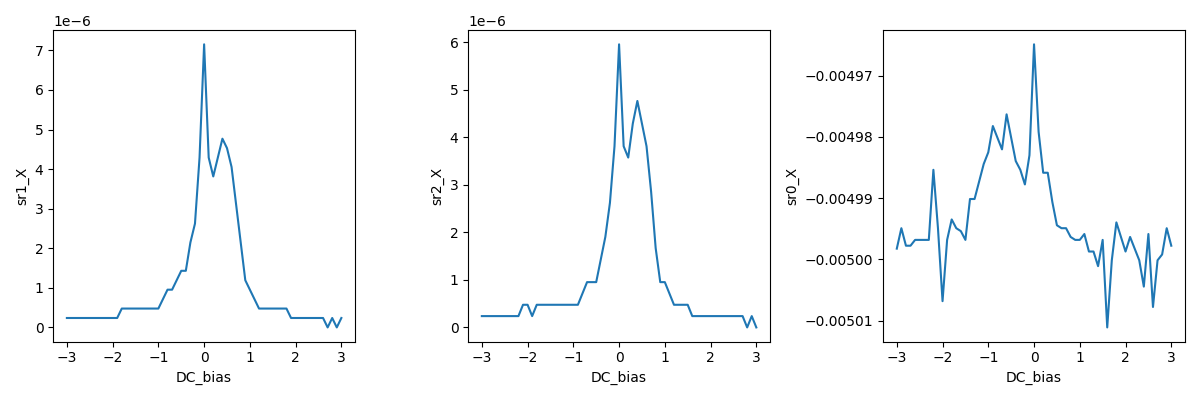

2026-06-17 13:40:26,155 [INFO] Completed in 0h 3m 13s


2026-06-17 13:40:26,157 [INFO] Data saved in C:\Users\DGG\VTI_local_data\aaron\20260617-QC0426\data\1\data.tsv.gz


Gate C liveness v2 done; TG parked at 0.


In [17]:
# === Gate C — cheap liveness on the provided contacts (v2, LS335 fix) ===
# Re-run of cell 30 (errored: per-point heater.sample_temperature poll hit the
# LS335/Grafana VISA-contention quirk). Fix: NO Lakeshore poll inside the loop.
# T is snapshotted once in meas_config; the Grafana logger keeps the time series.
# Otherwise identical: provided contacts, TG -3..+3 V trace, BG=Si=0, B=0.
# Current-bias (5 nA) -> modulation lives in Rxx (sr1/sr2); sr0 (I) ~constant.

# --- preconditions (state this cell assumes but does not set) ---
B0 = magnet.mag(); T0 = heater.sample_temperature()   # single reads OK; not per-point
assert abs(B0) < 0.01, f'field not ~0: {B0} T'
assert T0 < 1.5,       f'T not at base: {T0} K'
assert abs(k_bg.volt()) < 1e-6 and abs(k_2410.volt()) < 1e-6, 'BG/Si not parked at 0'
print(f'preconditions OK: B={B0:.4f} T, T={T0:.3f} K, TG(k_tg)={k_tg.voltage()} V, '
      f'BG={k_bg.volt()} V, Si={k_2410.volt()} V')

# --- route the provided contacts (Si 16/11 standing closures unmanaged/untouched) ---
mux.select({"source": "T2", "drain": "B7",
            "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5",
            "sr3+": "T5", "sr3-": "B6"})
print('routed:', mux.mc_fragment())

# --- 5 mV headroom on Rxx/Rxy channels so a CNP peak does not overload ---
for s_ in (sr1, sr2, sr3):
    s_.sensitivity(0.005)

# --- per-run measurement config ---
meas_config["sr0"] = "drain current on B7 (Ithaco x-1e6)"
meas_config["sr1"] = "Rxx T3-T4"
meas_config["sr2"] = "Rxx B4-B5"
meas_config["sr3"] = "Rxy T5-B6"
meas_config["bias_voltage"] = sr1.amplitude()
meas_config["lockin_freq"] = sr1.frequency()
meas_config["sr0_sens"] = sr0.sensitivity()
meas_config["sr1_sens"] = sr1.sensitivity()
meas_config["sr2_sens"] = sr2.sensitivity()
meas_config["sr3_sens"] = sr3.sensitivity()
meas_config["sample_temperature:"] = heater.sample_temperature()
meas_config["Si (V)"] = k_2410.volt()
meas_config["comments"] = ("Gate C liveness v2 (LS335 fix): TG -3..+3 V, BG=Si=0, B=0, "
                           "provided config src T2/drain B7; sr1/2/3 sens 5 mV")

# --- build station fresh ---
s = async_station(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment('Gate C liveness v2 - no LS335 per-point poll')

s.ramp(k_bg.volt, 0.0)   # BG already 0; never s.ramp(dc205_volt) -> no get

# Followed params: NO heater.sample_temperature (LS335 contention).
s.fp(k_bg.curr)
s.fp(k_2410.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)

s.plot(dc205_volt, sr1.X)
s.plot(dc205_volt, sr2.X)
s.plot(dc205_volt, sr0.X)

try:
    s.sweep(dc205_volt, spoints(-3.0, 3.0, 61), delay=2.0)
finally:
    dc205_volt(0.0)   # park TG via direct set
print('Gate C liveness v2 done; TG parked at 0.')


## HERA — 0 T TG-BG gate map (substrate for CNP / (n,D) calibration)

Foundational map (`gatemap.md`): axis-aligned raw-gate-voltage megasweep at B=0,
Si=0, provided contacts. BG[-4.5,4.5] x25 (slow) x TG[-6,6] x61 (fast) = 1525 pts.
TG fast range catches the CNP line (geometry slope ~-1.3, intercept ~0) at every
BG row. sens 0.5 mV (headroom over the ~1.4k liveness CNP peak). NO LS335 per-point
poll (contention fix). Stays inside validators; TG leakage is not directly
monitorable (DC205 has no current readback) so I watch the lock-ins + BG/Si current.

**Cost ~50-60 min** (1525 pts at ~1.7-2.3 s/pt incl. measure overhead + ~3 min row
turnaround; rig-card 2D rate is 2.0-2.5 s/pt). **Checkpoint at ~row 12** (BG~0,
~25 min): confirm the CNP ridge tracks diagonally and sens is not overloading at the
peak; continue / adjust sens / abort. E1 auto (in-envelope, B=0, gates within
validators). Output feeds the per-channel CNP-line fit and the (n,D) conversion.


pre: B=0.0025T T=1.165K Si=0.0V TG(k_tg)=0.0V BG=0.0V


2026-06-17 13:47:16,159 [INFO] Ramping k_bg_volt: 0.0 -> -4.5


2026-06-17 13:47:21,930 [INFO] Starting megasweep with ID 2


2026-06-17 13:47:21,931 [INFO] Minimum duration 0h 31m 20s


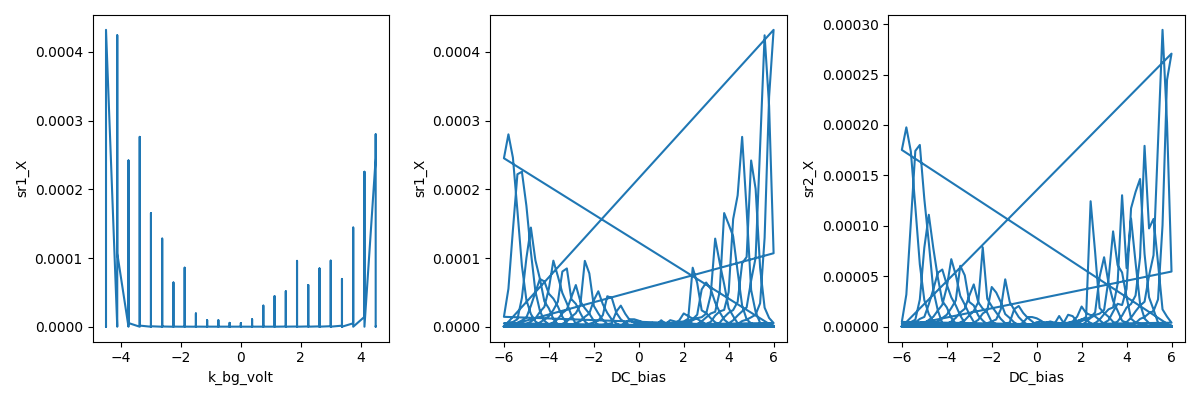

2026-06-17 14:51:44,063 [INFO] Completed in 1h 4m 21s


2026-06-17 14:51:44,064 [INFO] Data saved in C:\Users\DGG\VTI_local_data\aaron\20260617-QC0426\data\2\data.tsv.gz


gatemap done; TG & BG parked at 0.


In [18]:
# === 0 T TG-BG gate map (gatemap.md) — substrate for CNP/(n,D) calibration ===
# B=0, Si=0. Axis-aligned RAW-gate-voltage megasweep (cap ratios not yet trusted).
# Geometry prior: CNP slope dVtg/dVbg = -c_bg/c_tg ~ -1.3, intercept ~0 (CNP near
# origin, confirmed by Gate C liveness). TG fast [-6,+6] catches the CNP line at
# every BG row in [-4.5,+4.5]. Stays inside validators (TG [-6,7], BG [-4.5,4.5]).

# --- preconditions (state assumed, not set by this cell) ---
B0 = magnet.mag(); T0 = heater.sample_temperature()
assert abs(B0) < 0.01, f'field not ~0: {B0} T'
assert T0 < 1.5,       f'T not base: {T0} K'
assert abs(k_2410.volt()) < 1e-6, f'Si not at 0: {k_2410.volt()} V'
print(f'pre: B={B0:.4f}T T={T0:.3f}K Si={k_2410.volt()}V TG(k_tg)={k_tg.voltage()}V BG={k_bg.volt()}V')

# re-assert provided routing (idempotent; Si 16/11 unmanaged/untouched)
mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4",
            "sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})

# sens 0.5 mV: headroom over the ~1.4k oblique-cut CNP peak at 5 nA, resolves a
# kOhm ridge, safe against overload at the symmetric 2D CNP. (Config choice.)
for s_ in (sr1, sr2, sr3): s_.sensitivity(5e-4)

meas_config["sr0"]="drain current B7 (Ithaco x-1e6)"; meas_config["sr1"]="Rxx T3-T4"
meas_config["sr2"]="Rxx B4-B5"; meas_config["sr3"]="Rxy T5-B6"
meas_config["bias_voltage"]=sr1.amplitude(); meas_config["lockin_freq"]=sr1.frequency()
meas_config["sr0_sens"]=sr0.sensitivity(); meas_config["sr1_sens"]=sr1.sensitivity()
meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
meas_config["sample_temperature:"]=heater.sample_temperature(); meas_config["Si (V)"]=k_2410.volt()
meas_config["comments"]=("0T gatemap: BG[-4.5,4.5]x25 (slow) x TG[-6,6]x61 (fast), "
                         "Si=0, src T2/drain B7, sens 0.5mV")

s = async_station(meas_config)
s.add_comment('gatemap')
s.add_comment('0T TG-BG map; Si=0; provided contacts; CNP/(n,D) calibration substrate')

s.ramp(k_bg.volt, -4.5)   # slow-axis start (k_bg has a get -> s.ramp ok)
# TG fast axis starts at -6 via the sweep's first set; never s.ramp(dc205_volt).

s.fp(k_bg.curr); s.fp(k_2410.curr)              # NO LS335 poll (contention)
for lia in (sr0, sr1, sr2, sr3): s.fp(lia.X).fp(lia.P)

s.plot(k_bg.volt, sr1.X)
s.plot(dc205_volt, sr1.X)
s.plot(dc205_volt, sr2.X)

# slow = BG (25 rows), fast = TG (61 pts). fast_delay 1.2 s (~4 tau; CNP is a
# strong feature, not a weak tone), slow_delay 2.0 s.
try:
    s.megasweep(k_bg.volt,    spoints(-4.5, 4.5, 25),
                dc205_volt,    spoints(-6.0, 6.0, 61),
                slow_delay=2.0, fast_delay=1.2)
finally:
    dc205_volt(0.0); k_bg.volt(0.0)
print('gatemap done; TG & BG parked at 0.')


## HERA — SdH spot check A: electron n=+8e12, D=0, B 0->8T

Investigation `trilayer-stacking-fs-count.md` step 3 / `sdh-spot-check.md`. First of
two fixed-(n,D=0) field sweeps from zero. Pins the **onset**, the **tone content**
(FFT in 1/B vs F_L=82.7 T), and which density side gives cleaner SdH. A clean spot
check can be decisive on its own.

**Acquisition** (locked here, inherited by spot B + the fan): AC drive boosted to
**50 nA** (device R ~30 ohm at this n; 5 nA gave ~0.1uV, SdH buried), sens 20uV
(Rxx) / 50uV (Rxy, quantized Hall up to ~630 ohm at 8T), dwell 2.5 s (~8 tau, the
weak-tone settling floor), **B-step 12.5 mT** (Nyquist on F_L to ~1.7 T). 641 pts.

**Cost ~90 min** (blocking magnet ramp 0->8T ~58 min + 641x2.5s dwell ~27 min +
overhead). **Checkpoint at ~B=4T (~45 min):** confirm SdH emerging above onset, SNR
adequate, no overload; continue / adjust sens / abandon. Field is **left at 8T** so
spot B (hole, n=-8e12) descends 8->0 with no wasted return traverse.
E1 auto (in-envelope: |B|<=8T cap, gates within validators, D=0).


pre: B=0.0025T T=1.165K Si=0.0V


gates set: TG(k_tg)=3.838 BG=3.339 ; Ibias=50 nA
2026-06-17 15:03:32,770 [INFO] Starting sweep with ID 3


2026-06-17 15:03:32,770 [INFO] Minimum duration 0h 26m 42s


2026-06-17 15:15:29,734 [WARNING] ID 3 INTERRUPTED


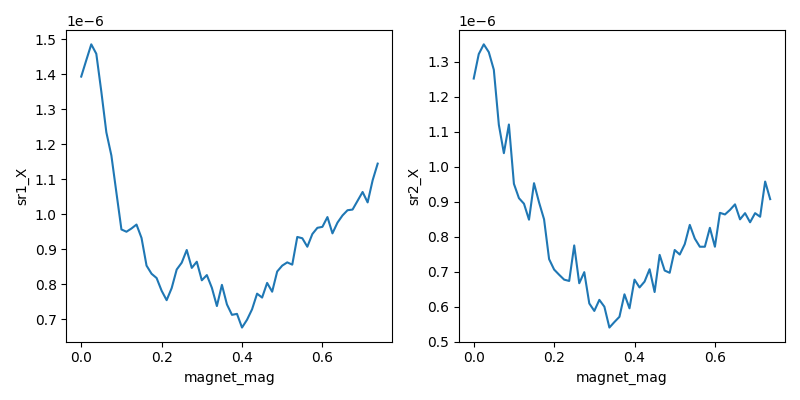

2026-06-17 15:15:30,084 [INFO] Completed in 0h 11m 56s


2026-06-17 15:15:30,085 [INFO] Data saved in C:\Users\DGG\VTI_local_data\aaron\20260617-QC0426\data\3\data.tsv.gz


SdH spot A done; field at 0.7417587397260273 T (left at 8T for descending spot B)


In [19]:
# === SdH spot check A — electron n=+8e12, D=0, B 0->8T (sdh-spot-check.md) ===
# Investigation step 3: pin onset, tone content vs F_L=82.7T, and which side is
# cleaner. Device R ~30 ohm at this n -> boost AC drive to 50 nA for SNR; sens 20uV
# (Rxx) / 50uV (Hall, R_xy up to ~630 ohm at 8T); dwell 2.5s (~8 tau, weak-tone
# settling floor); B-step 12.5 mT (Nyquist on F_L to ~1.7 T).

Vtg_op, Vbg_op = 3.838, 2.952   # calibration: n=+8e12, D=0

# --- preconditions ---
B0 = magnet.mag(); T0 = heater.sample_temperature()
assert abs(B0) < 0.05, f'field not ~0 at start: {B0} T'
assert T0 < 1.5,       f'T not base: {T0} K'
assert abs(k_2410.volt()) < 1e-6, f'Si not 0: {k_2410.volt()} V'
print(f'pre: B={B0:.4f}T T={T0:.3f}K Si={k_2410.volt()}V')

# routing + drive + sens
mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4",
            "sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
sr1.amplitude(5.0)                  # 5 V / 100 MOhm = 50 nA current bias
sr1.sensitivity(20e-6); sr2.sensitivity(20e-6); sr3.sensitivity(50e-6)

# ramp gates to operating point (within validators; TG+3.84<7, BG+2.95<4.5)
k_bg.volt(Vbg_op)
dc205_volt(Vtg_op)
time.sleep(3)
print(f'gates set: TG(k_tg)={k_tg.voltage():.3f} BG={k_bg.volt():.3f} ; Ibias={sr1.amplitude()/1e8*1e9:.0f} nA')

meas_config["sr0"]="drain I B7 (Ithaco x-1e6)"; meas_config["sr1"]="Rxx T3-T4"
meas_config["sr2"]="Rxx B4-B5"; meas_config["sr3"]="Rxy T5-B6"
meas_config["bias_voltage"]=sr1.amplitude(); meas_config["lockin_freq"]=sr1.frequency()
meas_config["sr0_sens"]=sr0.sensitivity(); meas_config["sr1_sens"]=sr1.sensitivity()
meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
meas_config["sample_temperature:"]=heater.sample_temperature(); meas_config["Si (V)"]=k_2410.volt()
meas_config["comments"]=("SdH spot A: n=+8e12 e D=0 (Vtg+3.84/Vbg+2.95), B 0->8T, "
                         "dB 12.5mT, 50nA bias, sens 20uV(Rxx)/50uV(Rxy), dwell 2.5s")

s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('electron n=+8e12 D=0; B 0->8T 12.5mT; 50nA; FS-count step 3')

# B already at 0; magnet.mag blocks per step (no pre-sleep; never s.ramp it).
s.fp(k_bg.curr); s.fp(k_2410.curr)
for lia in (sr0, sr1, sr2, sr3): s.fp(lia.X).fp(lia.P)
s.plot(magnet.mag, sr1.X); s.plot(magnet.mag, sr2.X)

s.sweep(magnet.mag, spoints(0.0, 8.0, 641), delay=2.5)
print('SdH spot A done; field at', magnet.mag(), 'T (left at 8T for descending spot B)')


## HERA — current diagnostic (sr0 overload check)
Resolve the 10.9 nA vs 50 nA discrepancy before re-running spot A: coarsen sr0 sens and confirm the amplitude->current transfer. Read-only on field/gates.

In [20]:
# === Diagnostic: resolve SdH bias current (sr0 read 10.9 nA vs expected 50 nA) ===
# Hypothesis: sr0 sens was 0.01 V (10 mV FS); a true 50 nA -> 50 mV at the Ithaco
# x1e6 -> overloads sr0 -> garbage readback. Coarsen sr0 to 0.1 V and re-measure;
# sweep amplitude to confirm the (linear) amplitude->current transfer (100 MOhm bias).
# Field sits at 0.74 T (interrupted); current bias is B-independent so this is valid.
print('state: B=', round(magnet.mag(),3), 'T ; sr1.amplitude=', sr1.amplitude(),
      'V ; f=', sr1.frequency(), 'Hz ; sr0.sens(old)=', sr0.sensitivity())
sr0.sensitivity(0.1)            # 100 mV FS: headroom for 50 nA * 1e6 = 50 mV
time.sleep(2)
for amp in (0.5, 1.0, 2.0, 5.0):
    sr1.amplitude(amp); time.sleep(3.0)
    I = sr0.X()/(-1e6)
    print(f'amp={amp:.2f}V -> I_drain={I*1e9:7.2f} nA (expect {amp/1e8*1e9:5.1f} nA) '
          f'| sr0_X={sr0.X()*1e3:+.2f} mV | Rxx_sr1={sr1.X()/I:6.1f} ohm | sr0 ovld={sr0.sensitivity()}')
print('left at amp=5 V')


state: B= 0.74 T ; sr1.amplitude= 5.0 V ; f= 13.0 Hz ; sr0.sens(old)= 0.01


amp=0.50V -> I_drain=   5.48 nA (expect   5.0 nA) | sr0_X=-5.46 mV | Rxx_sr1=  21.8 ohm | sr0 ovld=0.1


amp=1.00V -> I_drain=   9.94 nA (expect  10.0 nA) | sr0_X=-9.94 mV | Rxx_sr1=  21.1 ohm | sr0 ovld=0.1


amp=2.00V -> I_drain=  19.87 nA (expect  20.0 nA) | sr0_X=-19.88 mV | Rxx_sr1=  21.1 ohm | sr0 ovld=0.1


amp=5.00V -> I_drain=  49.61 nA (expect  50.0 nA) | sr0_X=-49.62 mV | Rxx_sr1=  22.4 ohm | sr0 ovld=0.1
left at amp=5 V


## HERA — SdH spot A v2 (sens corrected; relaunch)

Run 3 (v1) aborted on a current ambiguity that the diagnostic (cell 38) resolved:
bias is a correct **50 nA**; the 10.9 nA was sr0 overloading at 0.01 V sens. v2
corrects sens (sr0 0.1V, Rxx 10uV, Rxy 50uV) and drops the per-point gate-current
reads (gates static in a field sweep, ~30% faster). Otherwise identical: electron
n=+8e12, D=0, B 0->8T, dB 12.5 mT, dwell 2.5s. ~2 h (field sits at 0.74T, sweep
ramps to 0 first). Checkpoint ~B=4T. E1 auto.


pre: B=0.740T (will ramp to 0 at first point) T=1.169K Si=0.0V TG(k_tg)=3.838 BG=2.952


2026-06-17 15:19:14,813 [INFO] Starting sweep with ID 4


2026-06-17 15:19:14,814 [INFO] Minimum duration 0h 26m 42s


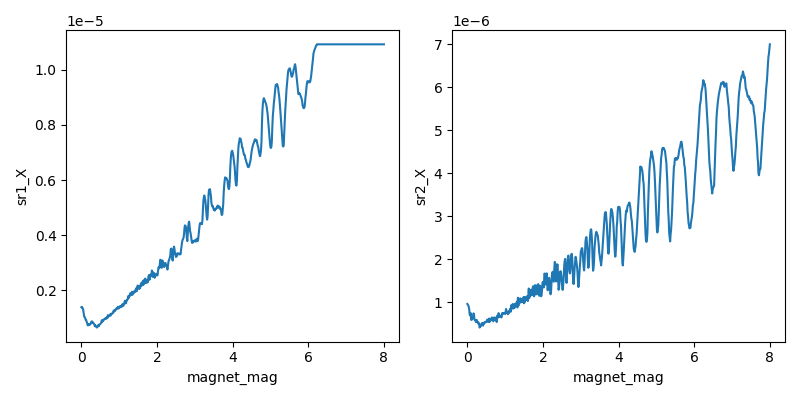

2026-06-17 17:22:15,108 [INFO] Completed in 2h 2m 59s


2026-06-17 17:22:15,108 [INFO] Data saved in C:\Users\DGG\VTI_local_data\aaron\20260617-QC0426\data\4\data.tsv.gz


SdH spot A v2 done; field at 8.005 T (left high for descending spot B)


In [21]:
# === SdH spot A v2 — electron n=+8e12, D=0, B 0->8T (sens corrected) ===
# Run 3 (v1) aborted: sr0 monitor overloaded at 0.01V sens (50nA*1e6=50mV). Diagnostic
# (cell 38) confirmed bias = 50 nA (linear in amplitude). Corrections: sr0 sens 0.1V;
# sr1/sr2 10uV (FS 200 ohm; Rxx ~13-30 ohm so far, ample headroom); sr3 50uV (Rxy to
# ~630 ohm at 8T). Gate-current fp dropped (gates static in a field sweep). dB 12.5mT,
# dwell 2.5s (~8 tau), B 0->8T. F_L=82.7 T.

Vtg_op, Vbg_op = 3.838, 2.952   # n=+8e12, D=0

# preconditions (field sits at ~0.74 T from the abort; sweep's first point ramps to 0)
T0 = heater.sample_temperature()
assert T0 < 1.5, f'T not base: {T0} K'
assert abs(k_2410.volt()) < 1e-6, f'Si not 0: {k_2410.volt()} V'
print(f'pre: B={magnet.mag():.3f}T (will ramp to 0 at first point) T={T0:.3f}K Si={k_2410.volt()}V '
      f'TG(k_tg)={k_tg.voltage():.3f} BG={k_bg.volt():.3f}')

mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4",
            "sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
sr1.amplitude(5.0)                                   # 50 nA bias
sr0.sensitivity(0.1); sr1.sensitivity(10e-6); sr2.sensitivity(10e-6); sr3.sensitivity(50e-6)

# gates already at operating point from v1; re-assert for reproducibility
k_bg.volt(Vbg_op); dc205_volt(Vtg_op); time.sleep(3)

meas_config["sr0"]="drain I B7 (Ithaco x-1e6)"; meas_config["sr1"]="Rxx T3-T4"
meas_config["sr2"]="Rxx B4-B5"; meas_config["sr3"]="Rxy T5-B6"
meas_config["bias_voltage"]=sr1.amplitude(); meas_config["lockin_freq"]=sr1.frequency()
meas_config["sr0_sens"]=sr0.sensitivity(); meas_config["sr1_sens"]=sr1.sensitivity()
meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
meas_config["sample_temperature:"]=heater.sample_temperature(); meas_config["Si (V)"]=k_2410.volt()
meas_config["comments"]=("SdH spot A v2: n=+8e12 e D=0 (Vtg+3.84/Vbg+2.95), B 0->8T, "
                         "dB 12.5mT, 50nA, sens sr0 0.1V/Rxx 10uV/Rxy 50uV, dwell 2.5s")

s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('electron n=+8e12 D=0; B 0->8T 12.5mT; 50nA; FS-count step 3 (v2)')

for lia in (sr0, sr1, sr2, sr3): s.fp(lia.X).fp(lia.P)   # no gate-current reads
s.plot(magnet.mag, sr1.X); s.plot(magnet.mag, sr2.X)

s.sweep(magnet.mag, spoints(0.0, 8.0, 641), delay=2.5)
print('SdH spot A v2 done; field at', round(magnet.mag(),3), 'T (left high for descending spot B)')


## HERA — SdH spot B: hole n=-8e12, D=0, B 8->0T (descending)

Second FS-count spot check, hole side. Magnet sits at 8T from spot A, so this
**descends 8->0** (no wasted traverse; also brings the magnet home). Hole side often
has more balanced ML/BL pockets -> a clearer f_ML, and this gives the cross-region /
mosaic check the investigation asks for. **Sens corrected** for the climbing MR seen
on spot A (electron sr1 hit 218 ohm @ 8T, overloaded 10uV): now 20uV Rxx (FS 400 ohm),
50uV Rxy. 50 nA, dB 12.5mT, dwell 2.5s. ~2 h.

Spot A result (electron): both Rxx channels show a **two-tone pair 17 + 70 T summing
to F_L (Hall)** = ABA signature, detrender-robust. Spot B tests whether the hole side
and the other region agree. After both, fan the cleaner side for F(n). E1 auto.


pre: B=8.002T T=1.274K Si=0.0V


gates set: TG(k_tg)=-3.690 BG=-1.391
2026-06-17 17:27:34,282 [INFO] Starting sweep with ID 5


2026-06-17 17:27:34,283 [INFO] Minimum duration 0h 26m 42s


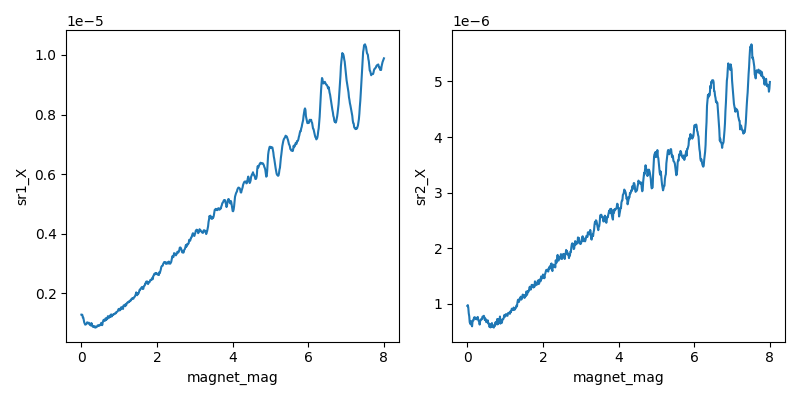

2026-06-17 19:25:12,059 [INFO] Completed in 1h 57m 37s


2026-06-17 19:25:12,060 [INFO] Data saved in C:\Users\DGG\VTI_local_data\aaron\20260617-QC0426\data\5\data.tsv.gz


SdH spot B done; field at 0.0 T (home)


In [22]:
# === SdH spot B — hole n=-8e12, D=0, B 8->0T descending (sdh-spot-check.md) ===
# Investigation step 3, hole side (ML/BL often more balanced -> clearer f_ML).
# Magnet sits at 8T from spot A -> descend (no wasted traverse; doubles as the
# magnet-home leg). Sens corrected for the climbing MR: 20uV Rxx (FS 400 ohm vs the
# ~220 ohm electron-side max), 50uV Rxy. 50 nA, dB 12.5mT, dwell 2.5s. F_L=82.7T.

Vtg_op, Vbg_op = -3.690, -2.838   # calibration: n=-8e12, D=0

# preconditions (magnet at ~8T; gates currently at electron point -> will be set)
T0 = heater.sample_temperature()
assert T0 < 1.5, f'T not base: {T0} K'
assert abs(k_2410.volt()) < 1e-6, f'Si not 0: {k_2410.volt()} V'
assert 7.5 < magnet.mag() < 8.05, f'expected magnet ~8T, got {magnet.mag()}'
print(f'pre: B={magnet.mag():.3f}T T={T0:.3f}K Si={k_2410.volt()}V')

mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4",
            "sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
sr1.amplitude(5.0)                                                   # 50 nA
sr0.sensitivity(0.1); sr1.sensitivity(20e-6); sr2.sensitivity(20e-6); sr3.sensitivity(50e-6)

# ramp gates from electron (+3.84/+2.95) to hole point (-3.69/-2.84) at B=8T.
# Both legal in validators. dc205_volt internal ramp 2V/s; k_bg via step.
k_bg.volt(Vbg_op); dc205_volt(Vtg_op); time.sleep(3)
print(f'gates set: TG(k_tg)={k_tg.voltage():.3f} BG={k_bg.volt():.3f}')

meas_config["sr0"]="drain I B7 (Ithaco x-1e6)"; meas_config["sr1"]="Rxx T3-T4"
meas_config["sr2"]="Rxx B4-B5"; meas_config["sr3"]="Rxy T5-B6"
meas_config["bias_voltage"]=sr1.amplitude(); meas_config["lockin_freq"]=sr1.frequency()
meas_config["sr0_sens"]=sr0.sensitivity(); meas_config["sr1_sens"]=sr1.sensitivity()
meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
meas_config["sample_temperature:"]=heater.sample_temperature(); meas_config["Si (V)"]=k_2410.volt()
meas_config["comments"]=("SdH spot B: n=-8e12 h D=0 (Vtg-3.69/Vbg-2.84), B 8->0T descending, "
                         "dB 12.5mT, 50nA, sens sr0 0.1V/Rxx 20uV/Rxy 50uV, dwell 2.5s")

s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('hole n=-8e12 D=0; B 8->0T descending 12.5mT; 50nA; FS-count step 3')

for lia in (sr0, sr1, sr2, sr3): s.fp(lia.X).fp(lia.P)
s.plot(magnet.mag, sr1.X); s.plot(magnet.mag, sr2.X)

s.sweep(magnet.mag, spoints(8.0, 0.0, 641), delay=2.5)   # descending
print('SdH spot B done; field at', round(magnet.mag(),3), 'T (home)')


## HERA — Landau fan, electron side, D=0 (FS-count F(n) refinement)

Firms the ABA call: the spot checks gave the two-tone pair (f_ML~17 + f_BL~70 = F_L)
at n=+8e12; this fan tracks **f_ML(n)+f_BL(n)=F_L(n) across density** (the model-
independent partition-robustness test, fs-count step 5), per-column FFT, on the
cleaner electron side. Grid: n=[2,10]e12 x33 (fast, paired gates at D=0, closure
verified |D|~0) x B 1.5-8T @20mT x326 (slow). 50nA; sens 20uV Rxx (sr1 ~218 ohm@8T =
54% of 400 FS -> no overload) / 50uV Rxy. fast_delay 1.5s.

**~7 h, unattended overnight** (operator reviews in AM, no Slack pings per their call).
In-envelope (|B|<=8T, gates within validators, D=0), overload-proofed. Parks
quiescent (TG=0, BG=0, B=0) at the end. The spot checks remain the 12.5mT high-res
anchor; a coarser fan does not overturn them (fs-count Verify). E1 auto.


fan grid: 326 B-rows x 33 n-cols | n 2.0e+12..1.0e+13 | TG 1.01..4.78 BG 0.78..3.68 | B 1.5..8.0T
pre: B=0.002T T=1.175K Si=0.0V


2026-06-17 19:34:23,287 [INFO] Starting multimegasweep with ID 6


2026-06-17 19:34:23,287 [INFO] Minimum duration 4h 39m 49s


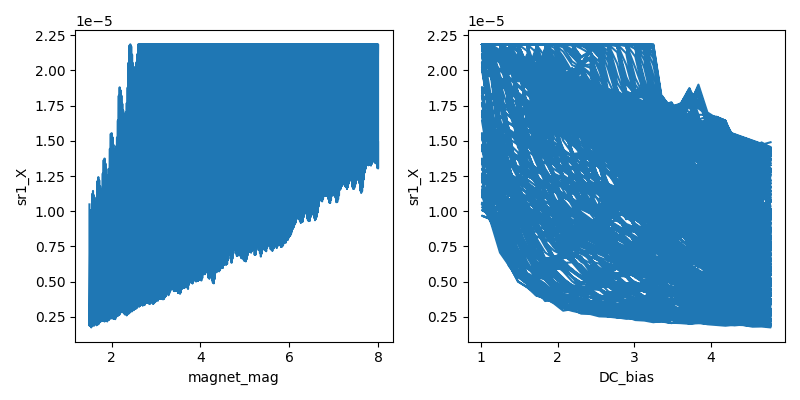

2026-06-18 02:45:44,424 [INFO] Completed in 7h 11m 20s


2026-06-18 02:45:44,425 [INFO] Data saved in C:\Users\DGG\VTI_local_data\aaron\20260617-QC0426\data\6\data.tsv.gz


FAN done. Parked: TG=0, BG=0, B= -0.001 T


In [23]:
# === Landau fan — electron side, D=0 (landau-fan-vti.md + fs-count step 4/5) ===
# F(n) partition-robustness test to firm the ABA call (spot checks gave the two-tone
# pair at n=+8e12; this tracks f_ML(n)+f_BL(n)=F_L(n) across density). Cleaner
# electron side. B (slow) x n-line (fast, paired gates at D=0).
#   n-line: 33 cols, n=[2,10]e12 cm^-2 (D=0). B: 1.5->8T @20mT (326 rows; resolves the
#   17/70T tones above ~2T - spot checks remain the 12.5mT anchor). 50nA; sens 20uV Rxx
#   (electron sr1 ~218 ohm@8T = 54% of 400 FS, no overload), 50uV Rxy. fast_delay 1.5s.
# Parks quiescent (gates 0, B 0) at the end for unattended hand-back.

import scipy.constants as cst
# --- D=0 gate line from the CNP calibration (run 2; ana cell 13) ---
n_off = -1.571e15                     # m^-2  (n_offset, CNP calibration)
ns_cm = np.linspace(2e12, 10e12, 33)  # electron density columns (cm^-2)
ns_m  = ns_cm * 1e4
Vbgs = (ns_m - n_off) * cst.e / (2 * c_bg)   # along D=0: c_tg*Vtg = c_bg*Vbg
Vtgs = (c_bg / c_tg) * Vbgs
assert Vtgs.max() < 7.0 and Vtgs.min() > -6.0, f'TG out of range: {Vtgs.min():.2f}..{Vtgs.max():.2f}'
assert Vbgs.max() < 4.5 and Vbgs.min() > -4.5, f'BG out of range: {Vbgs.min():.2f}..{Vbgs.max():.2f}'
B_vec = spoints(1.5, 8.0, 326)        # 20 mT step
print(f'fan grid: {len(B_vec)} B-rows x {len(ns_cm)} n-cols | n {ns_cm.min():.1e}..{ns_cm.max():.1e} '
      f'| TG {Vtgs.min():.2f}..{Vtgs.max():.2f} BG {Vbgs.min():.2f}..{Vbgs.max():.2f} | B {B_vec.min()}..{B_vec.max()}T')

# --- preconditions ---
T0 = heater.sample_temperature()
assert T0 < 1.5, f'T not base: {T0} K'
assert abs(k_2410.volt()) < 1e-6, f'Si not 0: {k_2410.volt()} V'
assert abs(magnet.mag()) < 0.05, f'expected magnet ~0 (home), got {magnet.mag()}'
print(f'pre: B={magnet.mag():.3f}T T={T0:.3f}K Si={k_2410.volt()}V')

mux.select({"source":"T2","drain":"B7","sr1+":"T3","sr1-":"T4",
            "sr2+":"B4","sr2-":"B5","sr3+":"T5","sr3-":"B6"})
sr1.amplitude(5.0)                                                    # 50 nA
sr0.sensitivity(0.1); sr1.sensitivity(20e-6); sr2.sensitivity(20e-6); sr3.sensitivity(50e-6)

meas_config["sr0"]="drain I B7 (Ithaco x-1e6)"; meas_config["sr1"]="Rxx T3-T4"
meas_config["sr2"]="Rxx B4-B5"; meas_config["sr3"]="Rxy T5-B6"
meas_config["bias_voltage"]=sr1.amplitude(); meas_config["lockin_freq"]=sr1.frequency()
meas_config["sr0_sens"]=sr0.sensitivity(); meas_config["sr1_sens"]=sr1.sensitivity()
meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
meas_config["sample_temperature:"]=heater.sample_temperature(); meas_config["Si (V)"]=k_2410.volt()
meas_config["comments"]=("landau fan electron D=0: n=[2,10]e12 x33 (fast, paired gates) x "
                         "B 1.5-8T @20mT x326 (slow), 50nA, sens 20uV Rxx/50uV Rxy, fast_delay 1.5s")

s = async_station(meas_config)
s.add_comment('landau-fan')
s.add_comment('landau-fan-vti')
s.add_comment('electron D=0 fan; n=2-10e12; B 1.5-8T; FS-count F(n) partition test')

# field starts at 0; first slow point ramps to 1.5T (blocking). gates set by fast axis.
for lia in (sr0, sr1, sr2, sr3): s.fp(lia.X).fp(lia.P)
s.plot(magnet.mag, sr1.X); s.plot(dc205_volt, sr1.X)

try:
    s.multimegasweep([magnet.mag], [B_vec],
                     [dc205_volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=2.0, fast_delay=1.5)
finally:
    # quiescent hand-back: park gates, ramp field home
    dc205_volt(0.0); k_bg.volt(0.0)
    magnet.mag(0.0)
print('FAN done. Parked: TG=0, BG=0, B=', round(magnet.mag(),3), 'T')


## HERA — session shutdown (operator request)
Return excitation to 5 nA (sr1.amplitude 0.5 V) and ground the device contacts via `mux.park()` (grounds managed lines only; Si 16/11 excluded -> preserved; not `qsw.reset()`). Gates/field already parked at 0.

In [24]:
# === Session shutdown (operator request) ===
# 1) excitation back to standing 5 nA; 2) ground the device contacts, Si untouched.
sr1.amplitude(0.5)                      # 0.5 V / 100 MOhm = 5 nA (standing excitation)
print('excitation:', sr1.amplitude(), 'V =', sr1.amplitude()/1e8*1e9, 'nA')

# mux.park() grounds every MANAGED contact line; Si lines 16/11 are excluded from the
# managed set, so they stay closed (Si gate preserved). This is NOT qsw.reset().
mux.park()
print('mux parked: managed contact lines grounded; routing now', mux._routing)

# state readback for the hand-back record
print('B =', round(magnet.mag(), 3), 'T | TG(k_tg) =', k_tg.voltage(), 'V | BG =',
      k_bg.volt(), 'V | Si(k_2410) =', k_2410.volt(), 'V | T =', heater.sample_temperature(), 'K')


excitation: 0.5 V = 5.0 nA


mux parked: managed contact lines grounded; routing now {}


B = 0.003 T | TG(k_tg) = 0.0 V | BG = 0.01425001 V | Si(k_2410) = 0.0 V | T = 1.165 K
